# KV cache from scratch: demo

This notebook loads GPT-2 small, generates text with every decoding path in the project, checks that they agree, shows how much memory the cache takes, and times eager decode against a CUDA graph on this machine. Reference measurements are the committed JSON files in `benchmarks/results/`; see `docs/results.md`.

## 1. Setup: model and tokenizer

In [1]:
import json
import time
import warnings
from pathlib import Path

# huggingface_hub imports tqdm.auto, which warns when ipywidgets is not installed.
warnings.filterwarnings('ignore', message='IProgress not found')

import tiktoken
import torch
from IPython.display import Image, Markdown, display

from kvcache import (
    CapturableKVCache,
    CUDAGraphDecoder,
    DynamicKVCache,
    StaticKVCache,
    generate_greedy_cached,
    generate_greedy_graph,
    generate_greedy_uncached,
    load_pretrained_gpt2,
)

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').exists())
HAS_CUDA = torch.cuda.is_available()
device = torch.device('cuda' if HAS_CUDA else 'cpu')
dtype = torch.float32
torch.set_float32_matmul_precision('highest')  # no TF32, as in the benchmarks
model = load_pretrained_gpt2(dtype=dtype, device=device)
# tiktoken is used only for demos (ADR-0005); the model works on token ids.
encoding = tiktoken.get_encoding('gpt2')
print(f'device: {device}' + (f' ({torch.cuda.get_device_name(0)})' if HAS_CUDA else ''))
print(f'parameters: {sum(p.numel() for p in model.parameters()):,}')

device: cuda (NVIDIA GeForce RTX 5060 Laptop GPU)
parameters: 124,439,808


## 2. Sixty greedy tokens with every decoding path

The uncached baseline forwards the whole sequence at every step. The dynamic and static caches forward one token per step. The graph path runs an eager prefill and then replays one captured decode step (CUDA only).

In [2]:
prompt_text = 'The key-value cache makes text generation faster because'
prompt = torch.tensor([encoding.encode(prompt_text)], device=device)
new_tokens = 60
P = prompt.shape[1]

outputs = {
    'uncached': generate_greedy_uncached(model, prompt, new_tokens),
    'dynamic': generate_greedy_cached(model, prompt, new_tokens, DynamicKVCache(model.config.n_layer)),
    'static': generate_greedy_cached(
        model, prompt, new_tokens,
        StaticKVCache.from_config(model.config, 1, dtype=dtype, device=device),
    ),
}
if HAS_CUDA:
    cache = CapturableKVCache.from_config(model.config, 1, dtype=dtype, device=device)
    outputs['graph'] = generate_greedy_graph(model, prompt, new_tokens, cache)
else:
    print('CUDA is not available: skipping the graph path.')

for name, ids in outputs.items():
    print(f'--- {name} ---')
    print(prompt_text + encoding.decode(ids[0, P:].tolist()))
reference = outputs['uncached']
for name, ids in outputs.items():
    print(f'{name:9s} identical to uncached: {torch.equal(ids, reference)}')

--- uncached ---
The key-value cache makes text generation faster because it's easier to read and write.

The key-value cache makes text generation faster because it's easier to read and write. The key-value cache makes text generation faster because it's easier to read and write. The key-value cache makes text generation faster because it's easier to
--- dynamic ---
The key-value cache makes text generation faster because it's easier to read and write.

The key-value cache makes text generation faster because it's easier to read and write. The key-value cache makes text generation faster because it's easier to read and write. The key-value cache makes text generation faster because it's easier to
--- static ---
The key-value cache makes text generation faster because it's easier to read and write.

The key-value cache makes text generation faster because it's easier to read and write. The key-value cache makes text generation faster because it's easier to read and write. The key-value

## 3. Memory of the cache

Keys plus values for one token take `2 · n_layer · n_embd · bytes` across all layers. A static cache allocates its whole capacity up front (`nbytes`) and reports what is in use (`used_nbytes`).

In [3]:
config = model.config
itemsize = torch.empty((), dtype=dtype).element_size()
per_token = 2 * config.n_layer * config.n_embd * itemsize
print(f'per token: 2 * {config.n_layer} * {config.n_embd} * {itemsize} = {per_token:,} bytes '
      f'({per_token / 1024:.0f} KiB)')

static = StaticKVCache.from_config(config, 1, dtype=dtype, device=device)
with torch.no_grad():
    model(prompt, cache=static)
print(f'capacity: {static.capacity} tokens, tokens in cache: {static.seq_len}')
print(f'nbytes (allocated):  {static.nbytes:,} = {per_token:,} * {static.capacity}')
print(f'used_nbytes (in use): {static.used_nbytes:,} = {per_token:,} * {static.seq_len}')
assert static.nbytes == per_token * static.capacity
assert static.used_nbytes == per_token * static.seq_len

per token: 2 * 12 * 768 * 4 = 73,728 bytes (72 KiB)
capacity: 1024 tokens, tokens in cache: 10
nbytes (allocated):  75,497,472 = 73,728 * 1024
used_nbytes (in use): 737,280 = 73,728 * 10


## 4. A short live timing: eager static cache against the CUDA graph

Batch size 1, a 512-token random prompt, 64 decode steps after an untimed prefill. Live numbers vary from run to run and with the GPU's power state (ADR-0013); the reference measurements are in the committed JSON files and `docs/results.md`.

In [4]:
if not HAS_CUDA:
    print('CUDA is not available: skipping the live timing.')
else:
    steps, context = 64, 512
    generator = torch.Generator().manual_seed(0)
    ids = torch.randint(0, config.vocab_size, (1, context), generator=generator).to(device)

    def eager_static_per_token() -> float:
        cache = StaticKVCache.from_config(config, 1, dtype=dtype, device=device)
        with torch.inference_mode():
            token = model(ids, cache=cache)[:, -1:].argmax(-1)
            torch.cuda.synchronize()
            start = time.perf_counter()
            for _ in range(steps):
                token = model(token, cache=cache)[:, -1:].argmax(-1)
            torch.cuda.synchronize()
        return (time.perf_counter() - start) / steps

    def graph_per_token() -> float:
        cache = CapturableKVCache.from_config(config, 1, dtype=dtype, device=device)
        with torch.no_grad():
            first = model(ids, cache=cache)[:, -1, :].argmax(dim=-1, keepdim=True)
        decoder = CUDAGraphDecoder(model, cache, steps + 1)
        decoder.out_tokens[:, :1].copy_(first)
        decoder.prepare(first, position=context, first_step=1)
        decoder.capture()  # capture cost excluded, as in the benchmarks
        torch.cuda.synchronize()
        start = time.perf_counter()
        decoder.replay(steps)
        torch.cuda.synchronize()
        return (time.perf_counter() - start) / steps

    eager_static_per_token(), graph_per_token()  # warm up
    eager = sorted(eager_static_per_token() for _ in range(3))[1]
    graph = sorted(graph_per_token() for _ in range(3))[1]
    print(f'eager static: {eager * 1e3:.2f} ms per token (median of 3)')
    print(f'CUDA graph:   {graph * 1e3:.2f} ms per token (median of 3)')
    print(f'speed-up:     {eager / graph:.1f}x')

eager static: 9.09 ms per token (median of 3)
CUDA graph:   2.10 ms per token (median of 3)
speed-up:     4.3x


## 5. Reference results

The figures are drawn from the committed JSON by `benchmarks/plots.py`; the table below is read from the same files.

**decode_gpu.png**

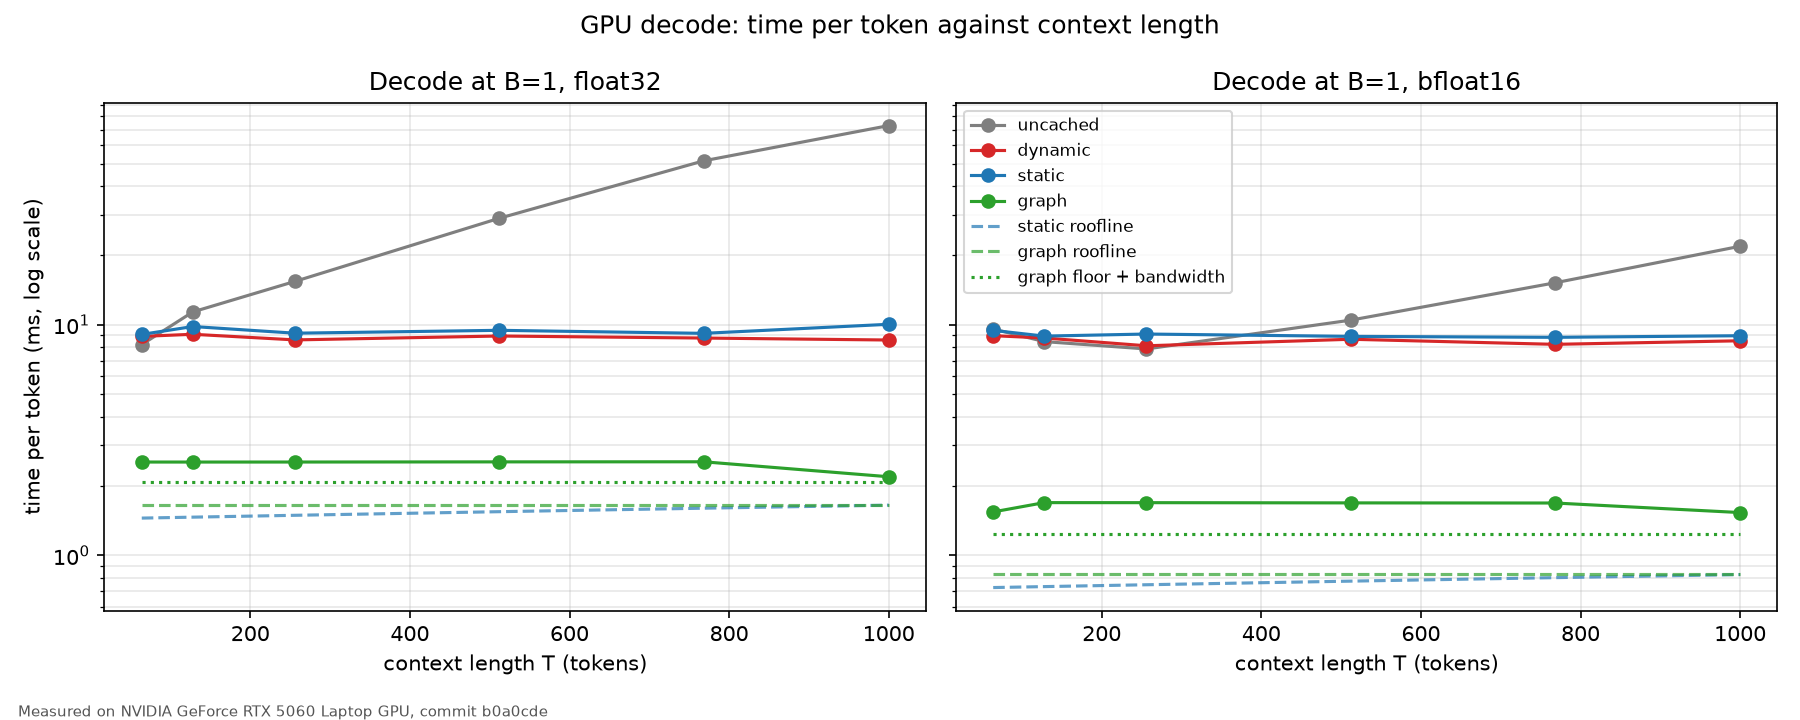

**time_breakdown.png**

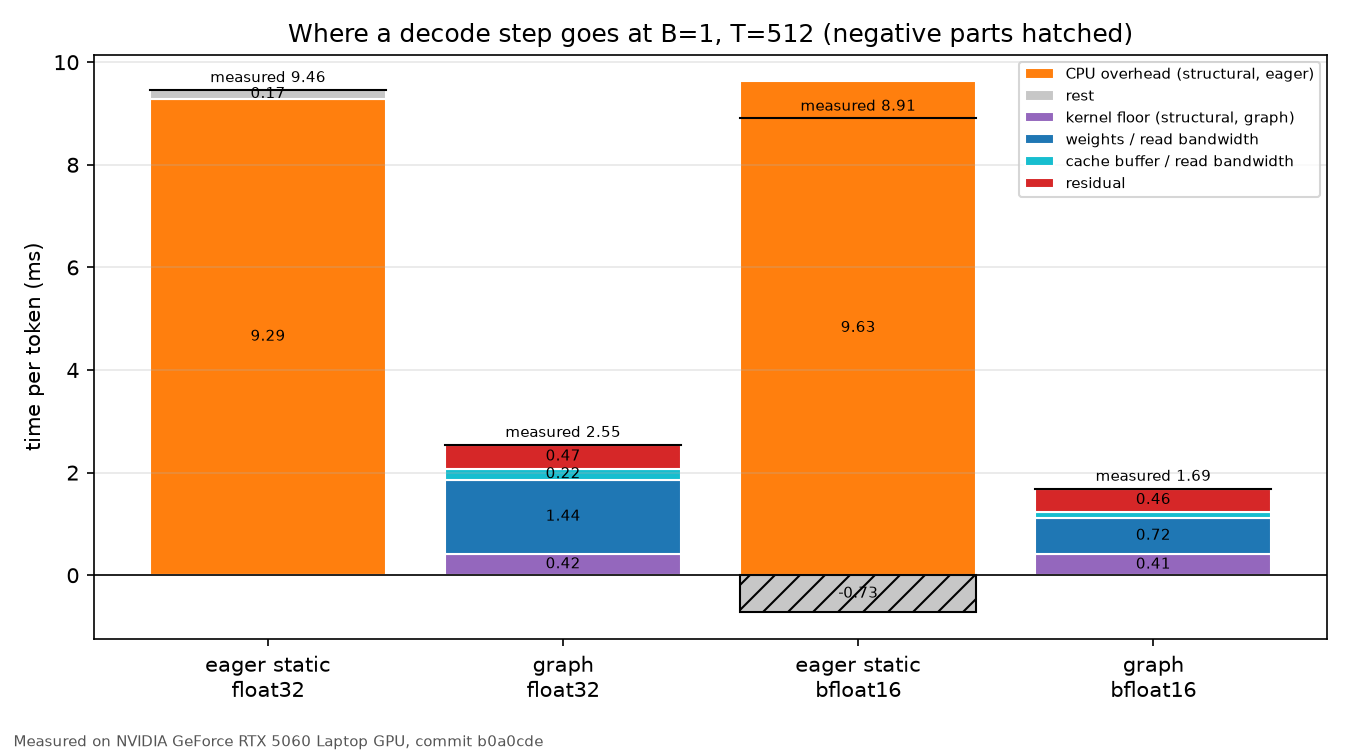

**batch_throughput.png**

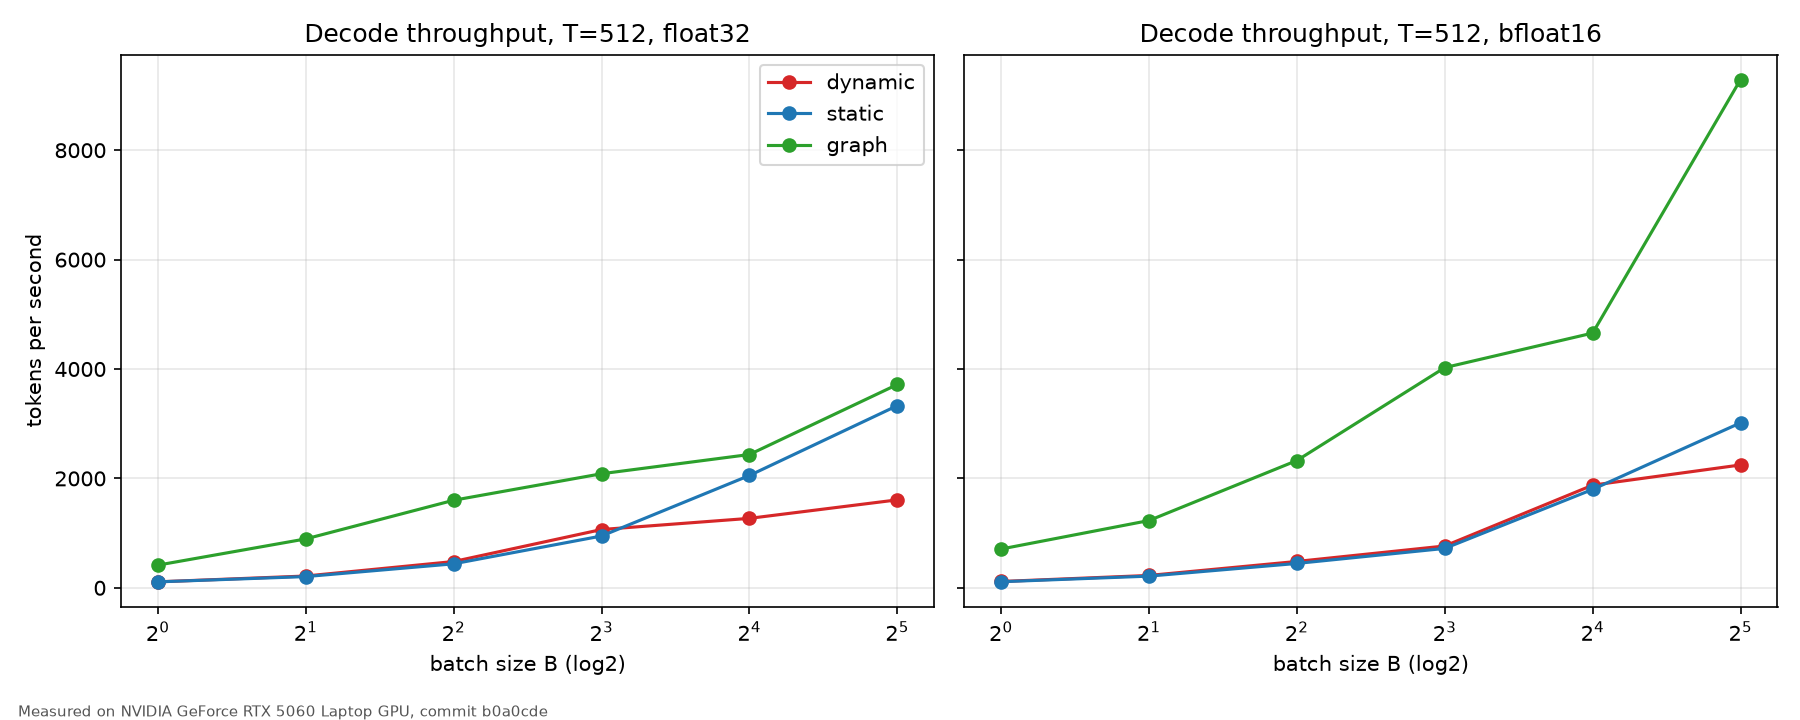

**memory.png**

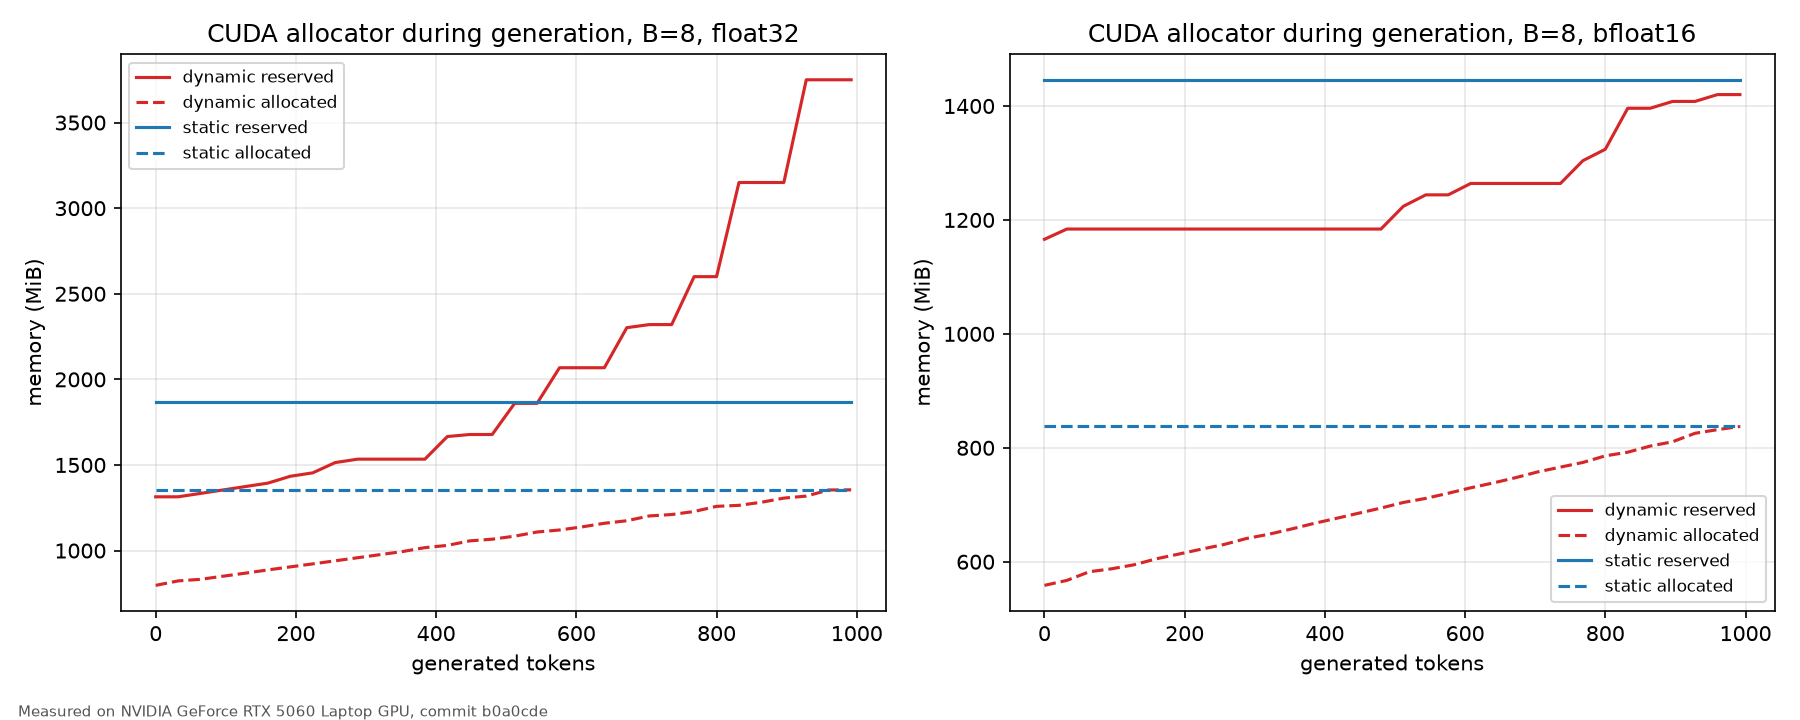

**capacity.png**

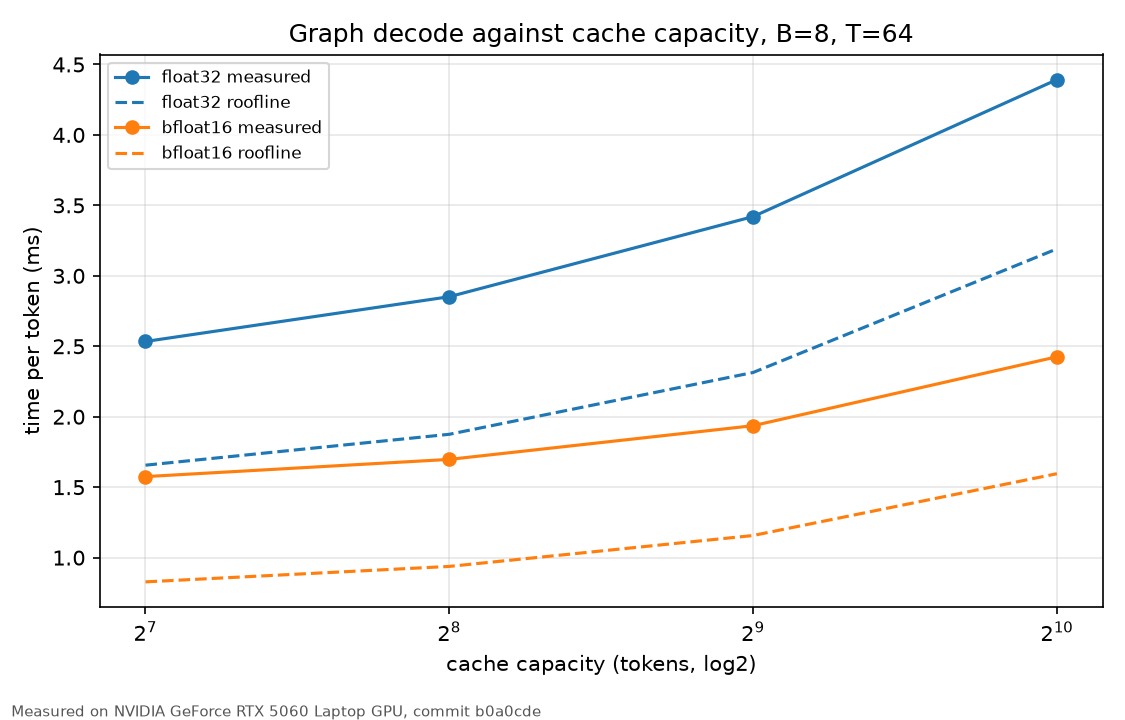

**roofline.png**

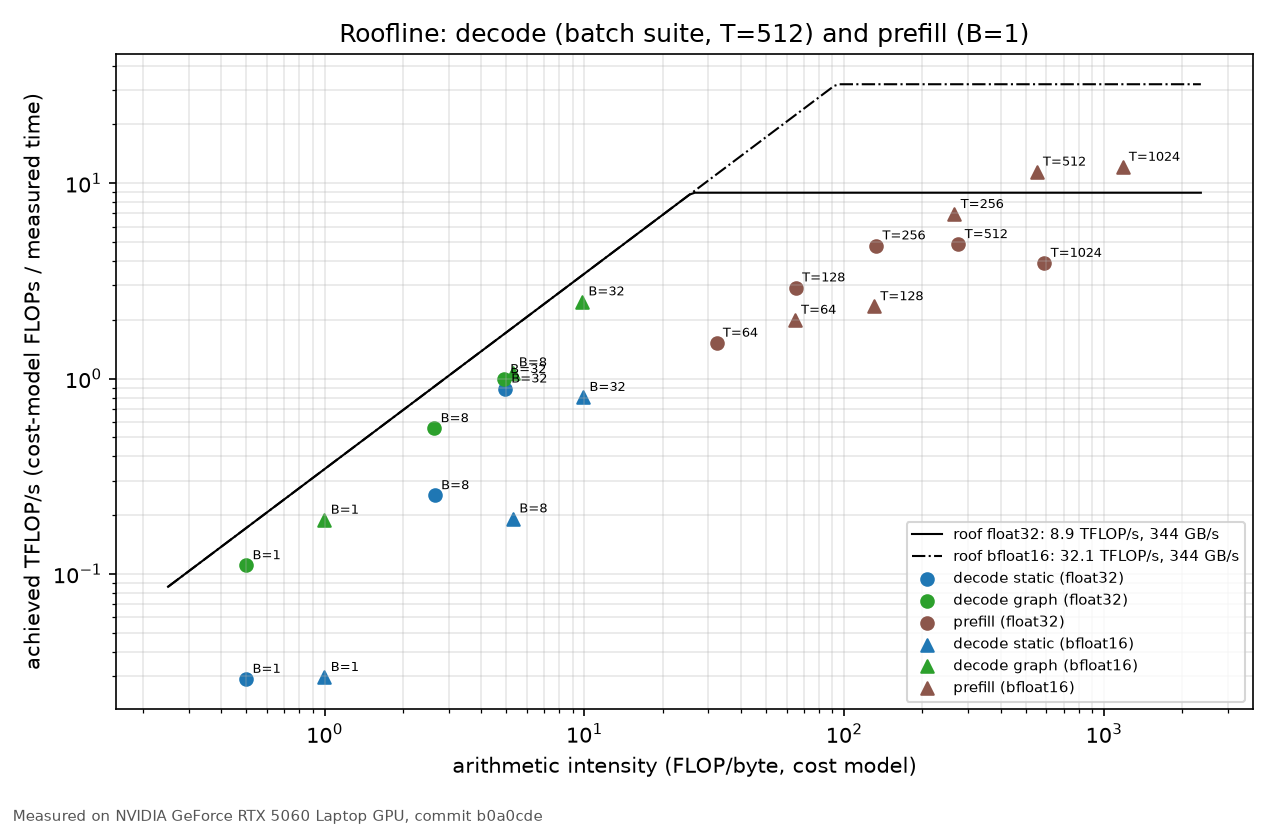

**decode_cpu.png**

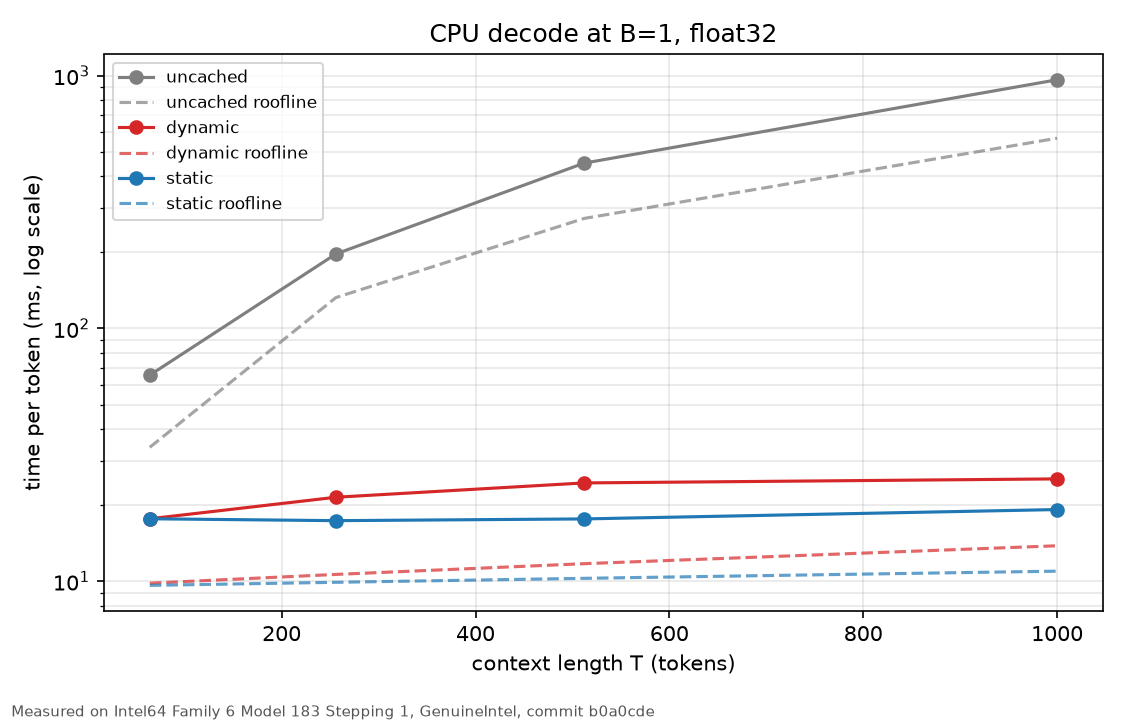

In [5]:
for name in ['decode_gpu', 'time_breakdown', 'batch_throughput', 'memory', 'capacity',
             'roofline', 'decode_cpu']:
    display(Markdown(f'**{name}.png**'))
    display(Image(filename=str(ROOT / 'docs' / 'figures' / f'{name}.png'), width=900))

In [6]:
def decode_row(path: Path, context: int) -> dict:
    payload = json.loads(path.read_text(encoding='utf-8'))
    records = payload['suites']['decode']['records']
    row = {r['variant']: r['median_s'] for r in records if r['context_len'] == context}
    return {'commit': payload['machine']['git_commit'][:7], **row}

results = ROOT / 'benchmarks' / 'results'
lines = ['| run | uncached | dynamic | static | graph | commit |', '|---|---|---|---|---|---|']
for label, file, context in [
    ('GPU float32, T=512', 'all_cuda_float32.json', 512),
    ('GPU bfloat16, T=512', 'all_cuda_bfloat16.json', 512),
    ('CPU float32, T=512', 'decode_cpu_float32.json', 512),
]:
    row = decode_row(results / file, context)
    cells = [f"{row[v] * 1e3:.3f}" if v in row else 'n/a' for v in ('uncached', 'dynamic', 'static', 'graph')]
    lines.append(f"| {label} | " + ' | '.join(cells) + f" | `{row['commit']}` |")
display(Markdown('Decode at B=1, ms per token (median, committed results):\n\n' + '\n'.join(lines)))

Decode at B=1, ms per token (median, committed results):

| run | uncached | dynamic | static | graph | commit |
|---|---|---|---|---|---|
| GPU float32, T=512 | 28.951 | 8.939 | 9.462 | 2.545 | `b0a0cde` |
| GPU bfloat16, T=512 | 10.472 | 8.654 | 8.906 | 1.690 | `b0a0cde` |
| CPU float32, T=512 | 450.549 | 24.486 | 17.641 | n/a | `b0a0cde` |